In [1]:
# Core Langgraph Frameworks
!pip install langgraph
!pip install langchain-openai
!pip install langchain
!pip install pydantic
!pip install grandalf
!pip install langchain-community
!pip install duckduckgo-search
!pip install -U ddgs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.9/125.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.0/572.0 kB 18.5 MB/s eta 0:00:00
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.6.1
    Uninstalling langchain-core-1.6.1:
      Successfully uninstalled langchain-core-1.6.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 62.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 7.4 MB/s eta 0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installe

In [2]:
# Import all dependencies

import os
from typing import Annotated, Literal, TypedDict
from langchain_community.tools import DuckDuckGoSearchRun
from langchain_core.messages import BaseMessage, HumanMessage, SystemMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import END, StateGraph, START
from langgraph.graph.message import add_messages
from IPython.display import display,Image
from pydantic import BaseModel, Field

/tmp/ipykernel_585/153217040.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.tools import DuckDuckGoSearchRun


In [3]:
# Set up OpenAI API Key
import os
from google.colab import userdata
os.environ["OPENAI_API_KEY"] = userdata.get('OPENAI_APIKEY')

In [4]:
# ==========================================
# Step 1: Initialize LLM
# ==========================================
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0.2)


In [5]:
# ==========================================
# Step 3: Setup Shared State
# ==========================================

class AgentState(TypedDict):
    user_query: str
    messages: Annotated[list[BaseMessage], add_messages]
    maths_data: str
    physics_data: str
    chemistry_data: str
    biology_data: str
    final_recommendation: str
    findings: str
    selected_agents: list[str]


In [6]:
# ==========================================
# Step 4: Setup schema for Supervisor routing decision
# ==========================================
class SupervisorRouting(BaseModel):
    selected_agents: list[Literal["maths", "physics", "chemistry", "biology", "synthesizer"]] = Field(
        description="Select 'maths' for maths, 'physics' for physics, 'chemistry' for chemistry, 'biology' for biology or 'synthesizer' if ready to finish"
    )

In [7]:
# ==========================================
# Step 5: Setup Supervior Agent
# ==========================================

def supervisor_agent(state: AgentState) -> dict:
    """Routes initial request to LLM to take decision."""
    structured_llm = llm.with_structured_output(SupervisorRouting)
    system_prompt = (
        "You are a Supervisor Routing Agent. Analyze the user query and decide which worker agents to invoke:\n"
        "- 'maths_agent': if the user asks for score in mathematics.\n"
        "- 'physics_agent': if the user asks for score in physics.\n"
        "- 'chemistry_agent': if the users asks for score in chemistry."
        "- 'biology_agent': if the user asks for score in biology."
    )

    decision: SupervisorRouting = structured_llm.invoke([
        SystemMessage(content=system_prompt),
        HumanMessage(content=state["user_query"])
    ])
    return {"selected_agents": decision.selected_agents}

In [8]:
# =======================================================
# Step 6: Setup Router Function for Conditional Edges
# =======================================================

def route_to_workers(state: AgentState) -> list[str]:
    """Returns the list of nodes to run in parallel based on supervisor's decision."""
    return state["selected_agents"]

In [9]:
# ==========================================
# Step 7: Setup Math Agent
# ==========================================

def maths_agent(state: AgentState) -> dict:
    return {"maths_data": "I scored Score: 90/100 in Maths"}

In [10]:
# ==========================================
# Step 8: Setup Physics Agent
# ==========================================

def physics_agent(state: AgentState) -> dict:
    return {"physics_data": "I scored Score: 80/100 in Physics"}



In [11]:
# ==========================================
# Step 9: Setup Chemistry Agent
# ==========================================

def chemistry_agent(state: AgentState) -> dict:
    return {"chemistry_data": "I scored Score: 70/100 in Chemistry"}

In [12]:
# ==========================================
# Step 9: Setup Biology Agent
# ==========================================

def biology_agent(state: AgentState) -> dict:
    return {"biology_data": "I scored Score: 60/100 in Biology"}

In [13]:
# ==========================================
# Step 10: Setup synthesizer Agent
# ==========================================

def synthesizer_agent(state: AgentState) -> dict:
    collected_findings = state["maths_data"] + "\n- " + state["physics_data"] + "\n- " + state["chemistry_data"] + "\n- " + state["biology_data"]
    state["findings"] = collected_findings
    prompt = SystemMessage(
        content="You are the Lead Synthesizer. Merge the following findings into a"
        " cohesive executive summary for the topic. "
        "Provide a clear final recommendation breakdown."
    )

    if not state.get("maths_data"):
        state["maths_data"] = "No score available for maths."
    if not state.get("physics_data"):
        state["physics_data"] = "No score available for physics."
    if not state.get("chemistry_data"):
        state["chemistry_data"] = "No score available for chemistry."
    if not state.get("biology_data"):
        state["biology_data"] = "No score available for biology."

    context = (
        f"--- MATHS DATA ---\n{state.get('maths_data', '')}\n\n"
        f"--- PHYSICS DATA ---\n{state.get('physics_data', '')}\n\n"
        f"--- CHEMISTRY DATA ---\n{state.get('chemistry_data', '')}\n\n"
        f"--- BIOLOGY DATA ---\n{state.get('biology_data', '')}"
    )


    response = llm.invoke([
        prompt,
        HumanMessage(content=f"Query: {state['user_query']}\n\n{context}")
    ])
    synthesizer_response = response.content

    return {"final_recommendation": synthesizer_response}

In [14]:
# ==========================================
# Step 11: Setup Graph
# ==========================================

builder = StateGraph(AgentState)

# Add Nodes
builder.add_node("supervisor_node", supervisor_agent)
builder.add_node("maths_node", maths_agent)
builder.add_node("physics_node", physics_agent)
builder.add_node("chemistry_node", chemistry_agent)
builder.add_node("biology_node", biology_agent)
builder.add_node("synthesizer_node", synthesizer_agent)

# Add Edges

builder.add_edge(START, "supervisor_node")

builder.add_conditional_edges(
    "supervisor_node",
    route_to_workers,
    {
        "maths": "maths_node",
        "physics": "physics_node",
        "chemistry": "chemistry_node",
        "biology": "biology_node"
    }
)

# All subject nodes now go back to the synthesizer_node
builder.add_edge("maths_node", "synthesizer_node")
builder.add_edge("physics_node", "synthesizer_node")
builder.add_edge("chemistry_node", "synthesizer_node")
builder.add_edge("biology_node", "synthesizer_node")

builder.add_edge("synthesizer_node", END)

# Compile Workflow Graph
graph = builder.compile()


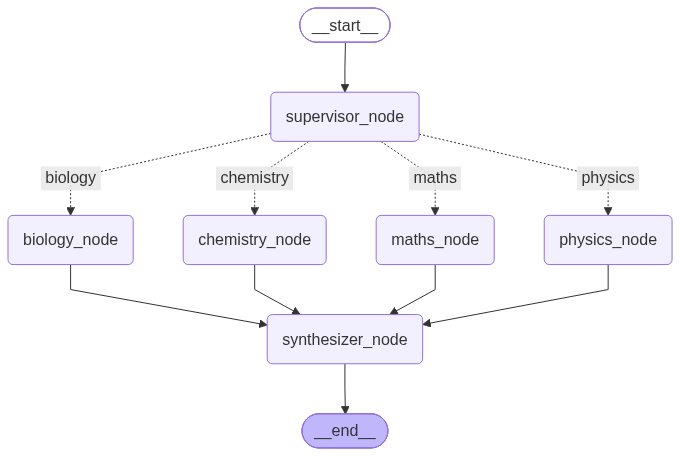

In [15]:
# ============================================================================
# PART 12: Show Chatbot Graph
# ============================================================================

display(Image(graph.get_graph().draw_mermaid_png()))

In [17]:
# ==========================================
# Step 13: Run the Graph
# ==========================================

query = "How much did i score in maths,physics,chemistry and biology ?"

result = graph.invoke({
        "user_query": query,
        "messages": []
    })

print(result["final_recommendation"])

**Executive Summary: Academic Performance Analysis**

This report provides a comprehensive overview of the academic performance in four core subjects: Mathematics, Physics, Chemistry, and Biology. The scores achieved in each subject are as follows:

- **Mathematics:** 90/100
- **Physics:** 80/100
- **Chemistry:** 70/100
- **Biology:** 60/100

**Performance Insights:**
1. **Mathematics:** The highest score of 90 indicates a strong grasp of mathematical concepts and problem-solving skills. This performance reflects a high level of proficiency and understanding in the subject.
   
2. **Physics:** Scoring 80 demonstrates solid knowledge and application of physical principles. This score suggests a good understanding, though there may be room for improvement in certain areas.

3. **Chemistry:** With a score of 70, there is a moderate understanding of chemical principles. This score indicates that while the foundational concepts are understood, further study and practice could enhance perfor